In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import sys
import shutil
import glob
import logging
import xml.etree.ElementTree as ET

from pathlib import Path
from io import StringIO
from typing import Dict, List, Optional, Union
from functools import reduce
import multiprocess as mp
from multiprocessing import cpu_count

import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt

from tqdm import tqdm
from tqdm.contrib.logging import logging_redirect_tqdm
import logging

import parmed
from openbabel import openbabel

from rdkit import Chem
from rdkit.Chem import rdmolops, AllChem, Draw
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

from plip.structure.preparation import PDBComplex, logger as PLIP_LOGGER
from plip.exchange.report import StructureReport
from plip.basic import config as PLIP_CONFIG

PLIP_LOGGER.setLevel(logging.ERROR)
PLIP_LOGGER.propagate = False


In [2]:
cwdir = os.getcwd()
dataset_dir = '/Users/joeyshin/Desktop/THG/BioEdaDatabase/dataset'
subdirs = ['biolip2_opt/',
           'pdbbind_opt_poly/',
           'pdbbind_opt_sm/']

def generate_PDBIDs():
    fcsv = os.path.join(dataset_dir, 'PDBIDs.csv')
    df_PDBIDs = pd.read_csv(fcsv)
    PDBIDs = (df_PDBIDs.T).to_numpy()
    PDBIDs = PDBIDs.tolist()
    PDBIDs = [[x for x in row if x is not None and not (isinstance(x, float) and math.isnan(x))]for row in PDBIDs]
    return PDBIDs

def generate_args():
    args = []
    for index, subdir in enumerate(subdirs):
        for PDBID in PDBIDs[index]:
            args.append((
                PDBID,
                subdir,
                os.path.join(dataset_dir, f'{subdir}{PDBID[:4]}/{PDBID}/{PDBID}_ligand_refined.sdf'),
                os.path.join(dataset_dir, f'{subdir}{PDBID[:4]}/{PDBID}/{PDBID}_ligand_refined.pdb'),
                os.path.join(dataset_dir, f'{subdir}{PDBID[:4]}/{PDBID}/{PDBID}_protein_refined.pdb'),
                os.path.join(dataset_dir, f'{subdir}{PDBID[:4]}/{PDBID}/{PDBID}_complex.pdb'),
                os.path.join(dataset_dir, f'{subdir}{PDBID[:4]}/{PDBID}/interaction.xml'),
                os.path.join(dataset_dir, f'{subdir}{PDBID[:4]}/{PDBID}/SaltBridgeProteinFragment'),
                os.path.join(dataset_dir, f'{subdir}{PDBID[:4]}/{PDBID}/SaltBridgeLigandFragment')
            ))
    return args

PDBIDs = generate_PDBIDs()
args = generate_args()

In [3]:
def extract_salt_bridge(xmlpath):
    xmlobj = ET.parse(xmlpath)
    binding_sites = xmlobj.findall("./bindingsite")
    # print(binding_sites)
    bs = [bs for bs in binding_sites if bs.findall("identifiers/longname")[0].text == "UNL"][0]
    pications = bs.findall("interactions/salt_bridges/salt_bridge")
    infos = []
    for pication in pications:
        info = {}
        for attr in pication:
            if attr.tag == 'ligcoo' or attr.tag == 'protcoo':
                for s in ['x', 'y', 'z']:
                    info[f'{attr.tag}_{s}'] = attr.find(s).text
            elif attr.tag == 'lig_idx_list' or attr.tag == 'prot_idx_list':
                info[attr.tag] = ' '.join([idx.text for idx in attr.findall('idx')])
            else:
                info[attr.tag] = attr.text
        infos.append(info)
    return infos

def make_identifier(code, resnr, restype, lig_idx_list, prot_idx_list):
    lig_idx_list = lig_idx_list.split()
    prot_idx_list = prot_idx_list.split()
    
    if len(lig_idx_list) > 1:
        lig_idx_list = f'{lig_idx_list[0]}-{lig_idx_list[len(lig_idx_list)-1]}'
    else:
        lig_idx_list = lig_idx_list[0]
    
    if len(prot_idx_list) > 1:
        prot_idx_list = f'{prot_idx_list[0]}-{prot_idx_list[len(prot_idx_list)-1]}'
    else:
        prot_idx_list = prot_idx_list[0]
    
    return f'{code}_{resnr}_{restype}_{lig_idx_list}_{prot_idx_list}'

def make_identifier_from_row(row):
    return make_identifier(row['full_PDBID'], row['resnr'], row['restype'], row['lig_idx_list'], row['prot_idx_list'])

In [4]:
df = []
err = []

for arg in tqdm(args):
    try:
        infos = extract_salt_bridge(arg[6])
        for info in infos:
            info['PDBID'] = arg[0][:4]
            info['full_PDBID'] = arg[0]
            info['subdir'] = arg[1]
            df.append(info)
    except Exception as e:
        err.append(arg)

print(len(err))
# print(LigNumberErr)

df = pd.DataFrame(df)
cols = ['PDBID'] + ['full_PDBID'] + ['subdir'] + list(df.columns[:-3])
df = df[cols]

df.index = [make_identifier_from_row(row) for index, row in df.iterrows()]
fcsv = os.path.join(cwdir, 'salt_bridge.csv')
df.to_csv(fcsv)
df

100%|██████████| 18928/18928 [00:10<00:00, 1767.86it/s]


0


,PDBID,full_PDBID,subdir,resnr,restype,reschain,prot_idx_list,resnr_lig,restype_lig,reschain_lig,dist,protispos,lig_group,lig_idx_list,ligcoo_x,ligcoo_y,ligcoo_z,protcoo_x,protcoo_y,protcoo_z
1am1_ADP_A_300_98_LYS_1-4_1606,1am1,1am1_ADP_A_300,biolip2_opt/,98,LYS,A,1606,1,UNL,Z,4.03,True,Phosphate,1 1 8 2 3 4,10.501,-5.055,-3.755,7.720,-2.147,-3.509
1am1_ADP_A_300_98_LYS_5-7_1606,1am1,1am1_ADP_A_300,biolip2_opt/,98,LYS,A,1606,1,UNL,Z,5.11,True,Phosphate,5 5 8 9 6 7,11.947,-4.146,-1.444,7.720,-2.147,-3.509
1apz_ASP_D_552_352_ARG_9-4_5164-5170,1apz,1apz_ASP_D_552,biolip2_opt/,352,ARG,D,5164 5167 5170,1,UNL,A,3.61,True,Carboxylate,9 4,24.471,49.350,-0.114,23.146,46.697,-2.180
1atp_ATP_E_355_59_LYS_9-13_989,1atp,1atp_ATP_E_355,biolip2_opt/,59,LYS,E,989,1,UNL,Z,3.39,True,Phosphate,9 9 10 11 12 13,11.968,9.868,-0.260,11.886,11.415,-3.274
1atp_ATP_E_355_59_LYS_5-7_989,1atp,1atp_ATP_E_355,biolip2_opt/,59,LYS,E,989,1,UNL,Z,3.27,True,Phosphate,5 5 8 12 6 7,14.471,10.520,-1.490,11.886,11.415,-3.274
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8a3h_IDC_A_500_33_HIS_10-20_517-522,8a3h,8a3h_IDC_A_500,pdbbind_opt_sm/,33,HIS,A,517 522,1,UNL,Z,5.38,True,Carboxylate,10 20,60.243,46.339,36.417,60.349,50.716,33.291
8cpa_AGF_A_309_70_HIS_24-25_1154-1160,8cpa,8cpa_AGF_A_309,pdbbind_opt_sm/,70,HIS,A,1154 1160,1,UNL,Z,4.57,True,Carboxylate,24 25,44.450,21.888,34.485,40.098,20.706,35.242
8cpa_AGF_A_309_128_ARG_24-25_2085-2091,8cpa,8cpa_AGF_A_309,pdbbind_opt_sm/,128,ARG,A,2085 2088 2091,1,UNL,Z,4.28,True,Carboxylate,24 25,44.450,21.888,34.485,42.531,18.303,35.824
8cpa_AGF_A_309_146_ARG_24-25_2347-2353,8cpa,8cpa_AGF_A_309,pdbbind_opt_sm/,146,ARG,A,2347 2350 2353,1,UNL,Z,3.75,True,Carboxylate,24 25,44.450,21.888,34.485,44.978,20.029,31.272


# Merge Duplicate Interactions

Combine rows if protein or ligand has attatched ring system to prevent double counting

In [5]:
grouped = df.groupby(['full_PDBID', 'resnr'])

In [6]:
def merge_duplicate(group):
    """
    Merge duplicate rows in a group

    Parameters
    ----------
    group: pandas.core.groupby.DataFrameGroupBy
        DataFrameGroupBy object grouped by ['full_PDBID', 'resnr']
    
    Return
    ------
    result_rows: pandas.DataFrame
        DataFrame of merged rows
    """

    if len(group) == 1:  # Return if interaction is unique
        return [group]

    group = group.copy()
    group['lig_idx_set'] = group['lig_idx_list'].apply(lambda x: set(map(int, str(x).split())))
    group['prot_idx_set'] = group['prot_idx_list'].apply(lambda x: set(map(int, str(x).split())))

    rows = group.to_dict('records')  # Convert to list of dicts
    adjacency_list = {i: set() for i in range(len(rows))}  # Graph representation

    # Build adjacency list for connected components
    for i in range(len(rows)):
        for j in range(i + 1, len(rows)):
            if rows[i]['lig_idx_set'].intersection(rows[j]['lig_idx_set']):  # Overlapping ligands
                adjacency_list[i].add(j)
                adjacency_list[j].add(i)

    # Find connected components using DFS (Depth-First Search)
    visited = set()
    merged_groups = []

    def dfs(node, component): # visits every node connection through recursion, builds list of connected nodes (component)
        if node in visited:
            return
        visited.add(node) # keeps history of visited nodes
        component.append(node) # appending connected nodes
        for neighbor in adjacency_list[node]: # for loop through every connection
            dfs(neighbor, component)

    for i in range(len(rows)):
        if i not in visited:
            component = []
            dfs(i, component)
            merged_groups.append(component) # add list of connected nodes (component) to merged_groups

    result_rows = []
    for component in merged_groups: # Merge each connected component
        merged_row = rows[component[0]].copy()
        for idx in component[1:]:
            merged_row['lig_idx_set'].update(rows[idx]['lig_idx_set'])
            merged_row['lig_idx_list'] = ' '.join(map(str, sorted(merged_row['lig_idx_set'])))
            merged_row['prot_idx_set'].update(rows[idx]['prot_idx_set'])
            merged_row['prot_idx_list'] = ' '.join(map(str, sorted(merged_row['prot_idx_set'])))
        
        result_rows.append({k: v for k, v in merged_row.items() if k not in ['lig_idx_set', 'prot_idx_set']})

    return [pd.DataFrame(result_rows)]

In [7]:
result_rows = []

for _, group in grouped: 
    result_rows.extend(merge_duplicate(group))

df = pd.concat(result_rows, ignore_index=True)
df.index = [make_identifier_from_row(row) for index, row in df.iterrows()]
fcsv = os.path.join(cwdir, 'salt_bridge.csv')
df.to_csv(fcsv)
df

,PDBID,full_PDBID,subdir,resnr,restype,reschain,prot_idx_list,resnr_lig,restype_lig,reschain_lig,dist,protispos,lig_group,lig_idx_list,ligcoo_x,ligcoo_y,ligcoo_z,protcoo_x,protcoo_y,protcoo_z
10gs_VWW_A_210_13_ARG_9-4_260-266,10gs,10gs_VWW_A_210,pdbbind_opt_sm/,13,ARG,A,260 263 266,1,UNL,A,4.42,True,Carboxylate,9 4,16.549,8.520,24.842,14.582,6.500,21.442
10gs_VWW_A_210_44_LYS_33-32_750,10gs,10gs_VWW_A_210,pdbbind_opt_sm/,44,LYS,A,750,1,UNL,A,3.60,True,Carboxylate,33 32,7.342,10.012,30.358,7.455,12.940,32.449
13gs_SAS_B_211_223_ARG_27-28_3541-3547,13gs,13gs_SAS_B_211,pdbbind_opt_sm/,223,ARG,B,3541 3544 3547,1,UNL,Z,4.06,True,Carboxylate,27 28,12.732,18.245,8.912,15.261,17.402,11.971
16pk_BIS_A_499_220_LYS_4-7_3451,16pk,16pk_BIS_A_499,pdbbind_opt_sm/,220,LYS,A,3451,1,UNL,Z,4.24,True,Phosphate,4 4 8 5 6 7,-10.543,44.710,-1.236,-14.270,42.709,-1.444
1a1b_ACE-DIP_C_100-103_15_ARG_16-19_309-312,1a1b,1a1b_ACE-DIP_C_100-103,pdbbind_opt_poly/,15,ARG,A,309 311 312,1,UNL,Z,4.61,True,Phosphate,16 16 15 17 18 19,48.055,10.105,26.062,43.653,10.018,27.433
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8a3h_IDC_A_500_33_HIS_10-20_517-522,8a3h,8a3h_IDC_A_500,pdbbind_opt_sm/,33,HIS,A,517 522,1,UNL,Z,5.38,True,Carboxylate,10 20,60.243,46.339,36.417,60.349,50.716,33.291
8cpa_AGF_A_309_128_ARG_24-25_2085-2091,8cpa,8cpa_AGF_A_309,pdbbind_opt_sm/,128,ARG,A,2085 2088 2091,1,UNL,Z,4.28,True,Carboxylate,24 25,44.450,21.888,34.485,42.531,18.303,35.824
8cpa_AGF_A_309_146_ARG_24-25_2347-2353,8cpa,8cpa_AGF_A_309,pdbbind_opt_sm/,146,ARG,A,2347 2350 2353,1,UNL,Z,3.75,True,Carboxylate,24 25,44.450,21.888,34.485,44.978,20.029,31.272
8cpa_AGF_A_309_197_HIS_24-25_3102-3108,8cpa,8cpa_AGF_A_309,pdbbind_opt_sm/,197,HIS,A,3102 3108,1,UNL,Z,5.11,True,Carboxylate,24 25,44.450,21.888,34.485,40.666,25.124,35.629


# Fragment Proteins

In [8]:
FRAG_SIDE_CHAIN = {
    'ASP': ['OD1', 'OD2', 'CG', 'CB', 'HB2', 'HB3'],
    'GLU': ['OE1', 'OE2', 'CD', 'CG', 'HG2', 'HG3'],
    'LYS': ['NZ', 'HZ1', 'HZ2', 'HZ3', 'CE', 'HE2', 'HE3'],
    'ARG': ['NH1', 'HH11', 'HH12', 'NH2', 'HH21', 'HH22', 'CZ', 'NE', 'HE1', 'CD', 'HD2', 'HD3'],
    'HIS': ['CE1', 'HE1', 'NE2', 'HE2', 'ND1', 'HD1', 'CD2', 'HD2', 'CG'],
    'HIE': ['CE1', 'HE1', 'NE2', 'HE2', 'ND1', 'CD2', 'HD2', 'CG'],
    'HID': ['CE1', 'HE1', 'NE2', 'ND1', 'HD1', 'CD2', 'HD2', 'CG']
}


def get_residue_fragment_mask(
    struct, resnr, restype, reschain
):
    residues = struct[f':{resnr}'].residues
    assert len(residues) == 1, "More than one residues are selected"
    assert residues[0].name == restype, f"Selected residue is not {restype}"
    assert residues[0].chain == reschain, f"Selected residue does not in chain {reschain}"

    # data type conversion
    resnr = int(resnr)
    
    # Gly terminal-O error correction
    if restype == 'GLY':
        mask = f':{resnr}@C,O,OXT,CA,HA*' 
    # His type
    elif restype == 'HIS':
        atom_names = []
        for atom in residues[0].atoms:
            atom_names.append(atom.name)
        
        if 'HD1' in atom_names and 'HE2' not in atom_names:
            histype = 'HID'
        elif 'HD1' not in atom_names and 'HE2' in atom_names:
            histype = 'HIE'
        elif 'HD1' in atom_names and 'HE2' in atom_names:
            histype = 'HIS'
        mask = f':{resnr}@{",".join(FRAG_SIDE_CHAIN[histype])}'
    else:
        mask = f':{resnr}@{",".join(FRAG_SIDE_CHAIN[restype])}'
    return mask


def struct_to_pdb_string(struct):
    strio = StringIO()
    struct.save(strio, format='pdb')
    strio.seek(0)
    return strio.read()


def hydrogen_coord_his(r_cg, r_cd2, r_nd1, deg, distance=1.09):
    theta = np.deg2rad(deg)
    r_cg = np.array(r_cg)
    r_cd2 = np.array(r_cd2)
    r_nd1 = np.array(r_nd1)

    r1 = r_cd2 - r_cg
    r2 = r_nd1 - r_cg

    e1 = r1 / np.linalg.norm(r1)
    e2 = r2 - r1 * np.dot(r2, r1)
    e2 = e2 / np.linalg.norm(e2)
    
    r = np.cos(theta) * e1 + np.sin(theta) * e2
    r = r * distance

    if np.linalg.norm(r - r2) < 1.0:
        r = np.cos(theta) * e1 - np.sin(theta) * e2
        r = r * distance

    return r


def add_hydrogen(struct, output_pdb):
    obConversion = openbabel.OBConversion()
    obConversion.SetInAndOutFormats("pdb", "pdb")
    
    ob_mol = openbabel.OBMol()
    obConversion.ReadString(ob_mol, struct_to_pdb_string(struct))
    
    resnames = set()
    atnames = []
    for atom in openbabel.OBMolAtomIter(ob_mol):
        residue = atom.GetResidue()
        resname = residue.GetName()
        atname = residue.GetAtomID(atom).strip()
        atnames.append(atname)
        resnames.add(resname)
    resnames = list(resnames)
    
    if len(resnames) == 1 and resnames[0] in ['GLU', 'ASP']:
        for atom in openbabel.OBMolAtomIter(ob_mol):
            atname = residue.GetAtomID(atom).strip()
            if atname == 'OD1' or atname == 'OE1':
                atom.SetFormalCharge(0)
                atom.SetImplicitHCount(0)
            if atname == 'OD2' or atname == 'OE2':
                atom.SetFormalCharge(-1)
                atom.SetImplicitHCount(0)
    elif 'OXT' in atnames:
        for atom in openbabel.OBMolAtomIter(ob_mol):
            atname = residue.GetAtomID(atom).strip()
            if atname == 'O':
                atom.SetFormalCharge(0)
                atom.SetImplicitHCount(0)
            if atname == 'OXT':
                atom.SetFormalCharge(-1)
                atom.SetImplicitHCount(0)
    
    if resname == 'HIS':
        if 'HD1' in atnames and 'HE2' in atnames:
            # manually add hydrogen to the 'CG' atom
            for atom in openbabel.OBMolAtomIter(ob_mol):
                atname = residue.GetAtomID(atom).strip()
                if atname == 'CG':
                    cg_atom = atom
                    r_cg = [atom.GetX(), atom.GetY(), atom.GetZ()]
                elif atname == 'CD2':
                    r_cd2 = [atom.GetX(), atom.GetY(), atom.GetZ()]
                elif atname == 'ND1':
                    r_nd1 = [atom.GetX(), atom.GetY(), atom.GetZ()]
            
            distance = 1.00
            deg = 120
            r = hydrogen_coord_his(r_cg, r_cd2, r_nd1, deg, distance)
            x, y, z = r[0] + r_cg[0], r[1] + r_cg[1], r[2] + r_cg[2]

            h_atom = ob_mol.NewAtom()
            h_atom.SetAtomicNum(1)
            h_atom.SetVector(x, y, z)
            ob_mol.AddBond(cg_atom.GetIdx(), h_atom.GetIdx(), 1)

            residue = cg_atom.GetResidue()
            residue.AddAtom(h_atom)
        else:
            ob_mol.AddHydrogens()
    else: 
        ob_mol.AddHydrogens()

    obConversion.WriteFile(ob_mol, output_pdb)

In [ ]:
def wrapper_prot_frag(arg): # args
    struct = parmed.load_file(arg[5])
    infos = extract_salt_bridge(arg[6])

    for interaction in infos:
        try:
            identifier = make_identifier(arg[0], interaction['resnr'], interaction['restype'], interaction['lig_idx_list'], interaction['prot_idx_list'])
            frag_name = f'{identifier}.pdb'

            frag_path = os.path.join(arg[7], frag_name)

            mask = get_residue_fragment_mask(
                struct,                              
                interaction['resnr'], interaction['restype'], interaction['reschain']
            )
            add_hydrogen(struct[mask], frag_path)
        except Exception as e:
            errs.append((arg[0], arg[1], interaction, str(e)))

PDBIDs = set(df['full_PDBID'].to_list())
args_salt_bridge = [arg for arg in args if arg[0] in PDBIDs]

for arg in args_salt_bridge:
    if not os.path.exists(arg[7]):
        os.makedirs(arg[7])

errs = []
with mp.Pool(cpu_count()) as pool:
    errs = list(tqdm(pool.imap(wrapper_prot_frag, args_salt_bridge), total=len(args_salt_bridge)))

  1%|          | 54/6286 [00:04<08:08, 12.76it/s]2025-07-09 14:03:29,489 [WARNING] [structure.py:935] parmed.structure: Could not find the head atom of the next template! Bond pattern may be wrong, which could lead to extra TER cards in a PDB file
2025-07-09 14:03:29,529 [WARNING] [structure.py:935] parmed.structure: Could not find the head atom of the next template! Bond pattern may be wrong, which could lead to extra TER cards in a PDB file
  6%|▋         | 400/6286 [00:27<10:49,  9.06it/s]==============================
*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders

  9%|▊         | 542/6286 [00:36<05:26, 17.58it/s]==============================
*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders

 10%|█         | 645/6286 [00:44<08:30, 11.06it/s]==============================
*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in O

In [11]:
for err in errs:
    if err is not None:
        print(err)

# Fragment Ligands

In [11]:
import os
import pandas as pd
from rdkit import Chem
from rdkit.Chem import AllChem, Draw
from tqdm import tqdm
import sys
sys.path.insert(0, '../')
from edautils.fragment import get_fg_set, select_fragment, write_sdf

In [10]:
# df = pd.read_csv("salt_bridges.csv", index_col=0)

salt_bridges = []

for index, row in tqdm(df.iterrows()):
    salt_bridges.append((
        row['PDBID'], 
        row['full_PDBID'],
        row['subdir'],
        os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/{row['full_PDBID']}_complex.pdb"),
        os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/interaction.xml"),
        os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/SaltBridgeProteinFragment"),
        os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/SaltBridgeLigandFragment"), 
        os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/{row['full_PDBID']}_ligand_refined.sdf"),
        index, 
        row['resnr'], 
        row['restype'],
        row['reschain'],
        row['lig_idx_list']
    ))

12097it [00:00, 26790.60it/s]


In [11]:
frags = []
lig_errs = []

for arg in tqdm(salt_bridges):
    try:
        mol = Chem.SDMolSupplier(arg[7], removeHs=False, sanitize=True)[0]
        # idx = mol.GetAtomWithIdx(int(arg[8]) - 1).GetNeighbors()[0].GetIdx()
        idx_list = [int(idx) - 1 for idx in arg[12].split()]
        fgs = get_fg_set(mol, False)

        target_atoms = set()
        for idx in idx_list:
            if idx in fgs:
                target_atoms.update(fgs[idx])
        
        frag = select_fragment(mol, fgs[idx])
        frag.SetProp("identifier", arg[8])

        if not os.path.isdir(arg[6]):
            os.mkdir(arg[6])
        write_sdf(frag, os.path.join(arg[6], f'{arg[8]}.sdf'))

        frag_no_h = Chem.RemoveHs(frag)
        AllChem.Compute2DCoords(frag_no_h)
        frags.append(frag_no_h)
    except Exception as e:
        lig_errs.append((arg[1], arg[2], e))


100%|██████████| 12097/12097 [00:30<00:00, 393.12it/s]


In [12]:
lig_errs

[('6cze_ITT_B_301',
  'pdbbind_opt_sm/',
  Boost.Python.ArgumentError('Python argument types in\n    rdkit.Chem.rdmolops.GetSymmSSSR(NoneType)\ndid not match C++ signature:\n    GetSymmSSSR(RDKit::ROMol {lvalue} mol, bool includeDativeBonds=False)')),
 ('6cze_ITT_B_301',
  'pdbbind_opt_sm/',
  Boost.Python.ArgumentError('Python argument types in\n    rdkit.Chem.rdmolops.GetSymmSSSR(NoneType)\ndid not match C++ signature:\n    GetSymmSSSR(RDKit::ROMol {lvalue} mol, bool includeDativeBonds=False)'))]

# Collect To Output

In [12]:
from edautils.fragment import read_pdb, extract_info

errPDBID = ['6cze_ITT_B_301']

In [14]:
valid_prot_smiles = {
    'C[NH3+]', # LYS
    'C.[NH4+]', # LYS
    'CNC(N)=[NH2+]', # ARG
    'C1=CNC=N1', # HIS
    'C1=C[NH+]=CN1', # HIS protonated
    'C1=NCNC1', # HIE
    'CC(=O)[O-]' # ASP
}

errs = []

for index, row in tqdm(df.iterrows(), total=len(df)):
    PDBID = row['full_PDBID']
    if PDBID in errPDBID:
        print(PDBID)
        df.drop(index, inplace=True)
    else:
        try:
            prot_frag_dir = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/SaltBridgeProteinFragment")
            lig_frag_dir = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/SaltBridgeLigandFragment")
                
            prot_frag_file = os.path.join(prot_frag_dir, f'{index}.pdb')
            lig_frag_file = os.path.join(lig_frag_dir, f'{index}.sdf')
        
            lig_frag = Chem.SDMolSupplier(lig_frag_file, removeHs=False)[0]
            prot_frag = read_pdb(prot_frag_file)
        
            lig_info = extract_info(lig_frag)
            prot_info = extract_info(prot_frag)
            
            assert prot_info['smiles'] in valid_prot_smiles, f'Invalid protin fragment: {prot_info["smiles"]}'
        
            df.loc[index, 'natoms0'] = lig_info['natoms']
            df.loc[index, 'charge0'] = lig_info['charge']
            df.loc[index, 'smiles0'] = lig_info['smiles']
            df.loc[index, 'natoms1'] = prot_info['natoms']
            df.loc[index, 'charge1'] = prot_info['charge']
            df.loc[index, 'smiles1'] = prot_info['smiles']
            df.loc[index, 'elements'] = ' '.join(lig_info['elements'] + prot_info['elements'])
            df.loc[index, 'xyz'] = ' '.join([f'{x:.3f}' for x in lig_info['xyz'].flatten()] + \
                [f'{x:.3f}' for x in prot_info['xyz'].flatten()])
        except Exception as e:
            errs.append((row['full_PDBID'], row['subdir'], str(e)))

# df_cc.to_csv('pi_cation.csv')
len(errs)

 88%|████████▊ | 10626/12097 [00:09<00:01, 834.99it/s] 

6cze_ITT_B_301
6cze_ITT_B_301


100%|██████████| 12097/12097 [00:11<00:00, 1039.41it/s]


14

In [14]:
err_codes = [err[0] for err in errs if err[2].startswith('Bad input file')]
len(err_codes)

0

In [ ]:
def wrapper_prot_frag(arg): # args wrapper
    struct = parmed.load_file(arg[5])
    infos = extract_salt_bridge(arg[6])

    for interaction in infos:
        try:
            identifier = make_identifier(arg[0], interaction['resnr'], interaction['restype'], interaction['lig_idx_list'], interaction['prot_idx_list'])
            frag_name = f'{identifier}.pdb'

            frag_path = os.path.join(arg[7], frag_name)

            mask = get_residue_fragment_mask(
                struct,                              
                interaction['resnr'], interaction['restype'], interaction['reschain']
            )
            add_hydrogen(struct[mask], frag_path)
        except Exception as e:
            errs.append((arg[0], arg[1], interaction, str(e)))

PDBIDs = set(df['full_PDBID'].to_list())
args_salt_bridge = [arg for arg in args if arg[0] in PDBIDs]

for arg in args_salt_bridge:
    if not os.path.exists(arg[7]):
        os.makedirs(arg[7])

errs = []
with mp.Pool(cpu_count()) as pool:
    errs = list(tqdm(pool.imap(wrapper_prot_frag, args_salt_bridge), total=len(args_salt_bridge)))

In [ ]:
def wrapper_prot_frag(row): # df wrapper
    complexPDB = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/{row['full_PDBID']}_complex.pdb")
    # interactionXML = os.path.join(dataset_dir, f'{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/interaction.xml')
    saltbridgeprot = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/SaltBridgeProteinFragment")

    struct = parmed.load_file(complexPDB)
    # infos = extract_salt_bridge(interactionXML)

    try:
        identifier = make_identifier(row['full_PDBID'], row['resnr'], row['restype'], row['lig_idx_list'], row['prot_idx_list'])
        frag_name = f'{identifier}.pdb'

        frag_path = os.path.join(saltbridgeprot, frag_name)

        mask = get_residue_fragment_mask(
            struct, 
            row['resnr'], row['restype'], row['reschain']
        )
        add_hydrogen(struct[mask], frag_path)
        err = None
    except Exception as e:
        err = (row['full_PDBID'], row['fullsubdir_PDBID'], str(e))
    return err

idx_err = []

for index, row in tqdm(df.iterrows(), total=len(df)):
    if row['full_PDBID'] in err_codes:
        idx_err.append(wrapper_prot_frag(row))

 62%|██████▏   | 7486/12095 [03:48<01:22, 55.76it/s] ==============================
*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders

 62%|██████▏   | 7496/12095 [03:50<02:47, 27.51it/s]==============================
*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders

100%|██████████| 12095/12095 [06:29<00:00, 31.05it/s] 


In [37]:
for err in idx_err:
    if err is not None:
        print(err)

## Recollect after Merged idx name fix

In [13]:
valid_prot_smiles = {
    'C[NH3+]', # LYS
    'CNC(N)=[NH2+]', # ARG
    'C1=CNC=N1', # HIS
    'C1=C[NH+]=CN1', # HIS protonated
    'CC(=O)[O-]' # ASP
}

errs = []

for index, row in tqdm(df.iterrows(), total=len(df)):
    PDBID = row['full_PDBID']
    if PDBID in errPDBID:
        print(PDBID)
        df.drop(index, inplace=True)
    else:
        try:
            prot_frag_dir = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/SaltBridgeProteinFragment")
            lig_frag_dir = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/SaltBridgeLigandFragment")
                
            prot_frag_file = os.path.join(prot_frag_dir, f'{index}.pdb')
            lig_frag_file = os.path.join(lig_frag_dir, f'{index}.sdf')
        
            lig_frag = Chem.SDMolSupplier(lig_frag_file, removeHs=False)[0]
            prot_frag = read_pdb(prot_frag_file)
        
            lig_info = extract_info(lig_frag)
            prot_info = extract_info(prot_frag)
            
            assert prot_info['smiles'] in valid_prot_smiles, f'Invalid protin fragment: {prot_info["smiles"]}'
        
            df.loc[index, 'natoms0'] = lig_info['natoms']
            df.loc[index, 'charge0'] = lig_info['charge']
            df.loc[index, 'smiles0'] = lig_info['smiles']
            df.loc[index, 'natoms1'] = prot_info['natoms']
            df.loc[index, 'charge1'] = prot_info['charge']
            df.loc[index, 'smiles1'] = prot_info['smiles']
            df.loc[index, 'elements'] = ' '.join(lig_info['elements'] + prot_info['elements'])
            df.loc[index, 'xyz'] = ' '.join([f'{x:.3f}' for x in lig_info['xyz'].flatten()] + \
                [f'{x:.3f}' for x in prot_info['xyz'].flatten()])
        except Exception as e:
            errs.append((row['full_PDBID'], row['subdir'], str(e)))

len(errs)

  0%|          | 0/12097 [00:00<?, ?it/s]

 88%|████████▊ | 10656/12097 [00:10<00:01, 908.76it/s] 

6cze_ITT_B_301
6cze_ITT_B_301


100%|██████████| 12097/12097 [00:13<00:00, 917.61it/s]


16

In [14]:
ErrPDBID1 = [err[0] for err in errs]
ErrPDBID1

for index, row in tqdm(df.iterrows(), total=len(df)):
    PDBID = row['full_PDBID']
    if PDBID in ErrPDBID1:
        df.drop(index, inplace=True)

df.to_csv('salt_bridge.csv')
df

100%|██████████| 12095/12095 [00:00<00:00, 29211.36it/s]


,PDBID,full_PDBID,subdir,resnr,restype,reschain,prot_idx_list,resnr_lig,restype_lig,reschain_lig,...,protcoo_y,protcoo_z,natoms0,charge0,smiles0,natoms1,charge1,smiles1,elements,xyz
10gs_VWW_A_210_13_ARG_9-4_260-266,10gs,10gs_VWW_A_210,pdbbind_opt_sm/,13,ARG,A,260 263 266,1,UNL,A,...,6.500,21.442,7.0,-1.0,CC(=O)[O-],13.0,1.0,CNC(N)=[NH2+],C C O O H H H C H H N C N H H N H H H H,15.010 9.987 24.792 16.115 8.924 24.830 16.520...
10gs_VWW_A_210_44_LYS_33-32_750,10gs,10gs_VWW_A_210,pdbbind_opt_sm/,44,LYS,A,750,1,UNL,A,...,12.940,32.449,7.0,-1.0,CC(=O)[O-],8.0,1.0,C[NH3+],C C O O H H H C H H N H H H H,7.740 7.933 30.366 7.452 9.433 30.354 7.116 9....
13gs_SAS_B_211_223_ARG_27-28_3541-3547,13gs,13gs_SAS_B_211,pdbbind_opt_sm/,223,ARG,B,3541 3544 3547,1,UNL,Z,...,17.402,11.971,14.0,-1.0,O=C([O-])C1=CC=CC=C1,13.0,1.0,CNC(N)=[NH2+],C C C C C C C O O H H H H H C H H N C N H H N ...,9.766 18.726 5.620 10.912 18.811 6.479 10.996 ...
16pk_BIS_A_499_220_LYS_4-7_3451,16pk,16pk_BIS_A_499,pdbbind_opt_sm/,220,LYS,A,3451,1,UNL,Z,...,42.709,-1.444,19.0,-2.0,CO[P@](=O)([O-])O[P@@](=O)([O-])C(C)(F)F,8.0,1.0,C[NH3+],P O O P O O O O C C F F C H H H H H H C H H N ...,-10.950 43.372 1.324 -10.705 44.156 2.708 -12....
1a1b_ACE-DIP_C_100-103_15_ARG_16-19_309-312,1a1b,1a1b_ACE-DIP_C_100-103,pdbbind_opt_poly/,15,ARG,A,309 311 312,1,UNL,Z,...,10.018,27.433,16.0,-2.0,O=P([O-])([O-])OC1=CC=CC=C1,13.0,1.0,CNC(N)=[NH2+],C C C C C C O P O O O H H H H H C H H N C N N ...,44.846 8.089 22.368 45.530 7.318 23.292 45.221...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8a3h_IDC_A_500_33_HIS_10-20_517-522,8a3h,8a3h_IDC_A_500,pdbbind_opt_sm/,33,HIS,A,517 522,1,UNL,Z,...,50.716,33.291,16.0,0.0,COC(C)OC,9.0,0.0,C1=CNC=N1,C C C O C O H H H H H H H H H H C N C H C H N H H,60.721 46.841 36.907 61.052 48.256 36.513 58.7...
8cpa_AGF_A_309_128_ARG_24-25_2085-2091,8cpa,8cpa_AGF_A_309,pdbbind_opt_sm/,128,ARG,A,2085 2088 2091,1,UNL,Z,...,18.303,35.824,7.0,-1.0,CC(=O)[O-],13.0,1.0,CNC(N)=[NH2+],C C O O H H H C H H N C N H H N H H H H,44.832 23.522 35.668 44.607 22.351 34.864 45.2...
8cpa_AGF_A_309_146_ARG_24-25_2347-2353,8cpa,8cpa_AGF_A_309,pdbbind_opt_sm/,146,ARG,A,2347 2350 2353,1,UNL,Z,...,20.029,31.272,7.0,-1.0,CC(=O)[O-],13.0,1.0,CNC(N)=[NH2+],C C O O H H H C H H N C N H H N H H H H,44.832 23.522 35.668 44.607 22.351 34.864 45.2...
8cpa_AGF_A_309_197_HIS_24-25_3102-3108,8cpa,8cpa_AGF_A_309,pdbbind_opt_sm/,197,HIS,A,3102 3108,1,UNL,Z,...,25.124,35.629,7.0,-1.0,CC(=O)[O-],9.0,0.0,C1=CNC=N1,C C O O H H H C N H C H C H N H,44.832 23.522 35.668 44.607 22.351 34.864 45.2...


## Remove Neutral Fragments

In [15]:
df_charged = df.query("charge0 != 0 and charge1 != 0")
df_nn = df.query("charge0 == 0 and charge1 == 0")
df_nc = df.query("charge0 == 0 or charge1 == 0")
print(len(df_charged))
print(len(df_nn))
print(len(df_nc))
df_charged

8364
247
3690


,PDBID,full_PDBID,subdir,resnr,restype,reschain,prot_idx_list,resnr_lig,restype_lig,reschain_lig,...,protcoo_y,protcoo_z,natoms0,charge0,smiles0,natoms1,charge1,smiles1,elements,xyz
10gs_VWW_A_210_13_ARG_9-4_260-266,10gs,10gs_VWW_A_210,pdbbind_opt_sm/,13,ARG,A,260 263 266,1,UNL,A,...,6.500,21.442,7.0,-1.0,CC(=O)[O-],13.0,1.0,CNC(N)=[NH2+],C C O O H H H C H H N C N H H N H H H H,15.010 9.987 24.792 16.115 8.924 24.830 16.520...
10gs_VWW_A_210_44_LYS_33-32_750,10gs,10gs_VWW_A_210,pdbbind_opt_sm/,44,LYS,A,750,1,UNL,A,...,12.940,32.449,7.0,-1.0,CC(=O)[O-],8.0,1.0,C[NH3+],C C O O H H H C H H N H H H H,7.740 7.933 30.366 7.452 9.433 30.354 7.116 9....
13gs_SAS_B_211_223_ARG_27-28_3541-3547,13gs,13gs_SAS_B_211,pdbbind_opt_sm/,223,ARG,B,3541 3544 3547,1,UNL,Z,...,17.402,11.971,14.0,-1.0,O=C([O-])C1=CC=CC=C1,13.0,1.0,CNC(N)=[NH2+],C C C C C C C O O H H H H H C H H N C N H H N ...,9.766 18.726 5.620 10.912 18.811 6.479 10.996 ...
16pk_BIS_A_499_220_LYS_4-7_3451,16pk,16pk_BIS_A_499,pdbbind_opt_sm/,220,LYS,A,3451,1,UNL,Z,...,42.709,-1.444,19.0,-2.0,CO[P@](=O)([O-])O[P@@](=O)([O-])C(C)(F)F,8.0,1.0,C[NH3+],P O O P O O O O C C F F C H H H H H H C H H N ...,-10.950 43.372 1.324 -10.705 44.156 2.708 -12....
1a1b_ACE-DIP_C_100-103_15_ARG_16-19_309-312,1a1b,1a1b_ACE-DIP_C_100-103,pdbbind_opt_poly/,15,ARG,A,309 311 312,1,UNL,Z,...,10.018,27.433,16.0,-2.0,O=P([O-])([O-])OC1=CC=CC=C1,13.0,1.0,CNC(N)=[NH2+],C C C C C C O P O O O H H H H H C H H N C N N ...,44.846 8.089 22.368 45.530 7.318 23.292 45.221...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7ng7_UCW_A_602_93_ASP_14_1565-1566,7ng7,7ng7_UCW_A_602,biolip2_opt/,93,ASP,A,1565 1566,1,UNL,Z,...,-9.876,-15.815,14.0,1.0,C[NH+](C)C,7.0,-1.0,CC(=O)[O-],C C N C H H H H H H H H H H C H H C O O H,-17.250 -9.510 -11.432 -19.116 -10.805 -10.738...
7ng7_UCW_A_602_93_ASP_9_1565-1566,7ng7,7ng7_UCW_A_602,biolip2_opt/,93,ASP,A,1565 1566,1,UNL,Z,...,-9.876,-15.815,14.0,1.0,C[NH+](C)C,7.0,-1.0,CC(=O)[O-],C N C C H H H H H H H H H H C H H C O O H,-17.796 -11.440 -12.784 -17.961 -11.973 -14.16...
7wf7_S1P_A_401_13_LYS_22-23_267,7wf7,7wf7_S1P_A_401,biolip2_opt/,13,LYS,A,267,1,UNL,Z,...,134.271,102.884,9.0,-2.0,COP(=O)([O-])[O-],8.0,1.0,C[NH3+],C O P O O O H H H C H H N H H H H,157.583 133.633 109.762 158.014 133.870 108.49...
8cpa_AGF_A_309_128_ARG_24-25_2085-2091,8cpa,8cpa_AGF_A_309,pdbbind_opt_sm/,128,ARG,A,2085 2088 2091,1,UNL,Z,...,18.303,35.824,7.0,-1.0,CC(=O)[O-],13.0,1.0,CNC(N)=[NH2+],C C O O H H H C H H N C N H H N H H H H,44.832 23.522 35.668 44.607 22.351 34.864 45.2...


# H-Bond duplicate Validation

- no exact idx overlap in hbonds and salt_bridges  

In [61]:
df_hbonds = pd.read_csv('../hbonds/hbonds.csv', index_col=0)

df['resnr'] = df['resnr'].astype(int)
df_hbonds['resnr'] = df_hbonds['resnr'].astype(int)

merged_df = pd.merge(df, df_hbonds, on=['full_PDBID', 'resnr'], how='inner')

print(len(merged_df))

rows_to_add = []

for index, row in tqdm(merged_df.iloc[14:16].iterrows(), total=len(merged_df)):
    protisdon = row['protisdon']

    lig_idx_list = row['lig_idx_list'].split()
    prot_idx_list = row['prot_idx_list'].split()
    donoridx = row['donoridx']
    acceptoridx = row['acceptoridx']

    print(lig_idx_list)
    print(prot_idx_list)
    print(donoridx)
    print(acceptoridx)

    if protisdon:
        if donoridx in prot_idx_list and acceptoridx in lig_idx_list:
            rows_to_add.append(row)
    else:
        if acceptoridx in prot_idx_list and donoridx in lig_idx_list:
            rows_to_add.append(row)


# merged_df.to_csv('hbond_saltbridge.csv')
merged_idx_df = pd.DataFrame(rows_to_add)
print(len(merged_idx_df))

3603


  0%|          | 2/3603 [00:00<00:00, 5210.32it/s]

['11', '7']
['296']
296
8
['5', '5', '8', '9', '6', '7']
['11624', '11627', '11630']
11627
12
0


In [ ]:
charged_merged_df = merged_df.copy()

for index, row in tqdm(merged_df.iterrows(), total=len(merged_df)):
    if row['charge0_x'] == 0 or row['charge0_x'] == 0:
        charged_merged_df = charged_merged_df.drop(index)


charged_merged_df

100%|██████████| 3603/3603 [00:01<00:00, 3306.11it/s]


,PDBID_x,full_PDBID,subdir_x,resnr,restype_x,reschain_x,prot_idx_list,resnr_lig_x,restype_lig_x,reschain_lig_x,...,protcoo_y_y,protcoo_z_y,natoms0_y,charge0_y,smiles0_y,natoms1_y,charge1_y,smiles1_y,elements_y,xyz_y
0,16pk,16pk_BIS_A_499,pdbbind_opt_sm/,220,LYS,A,3451,1,UNL,Z,...,42.709,-1.444,19.0,-2.0,CO[P@](=O)([O-])O[P@@](=O)([O-])C(C)(F)F,8.0,1.0,C[NH3+],P O O P O O O O C C F F C H H H H H H C H H N ...,-10.950 43.372 1.324 -10.705 44.156 2.708 -12....
1,1a1b,1a1b_ACE-DIP_C_100-103,pdbbind_opt_poly/,15,ARG,A,309 311 312,1,UNL,Z,...,10.139,27.828,12.0,0.0,CNC(C)=O,13.0,1.0,CNC(N)=[NH2+],C O C N C H H H H H H H C H H N C N N H H H H H H,41.878 7.648 24.755 41.686 8.868 24.882 41.895...
2,1a1b,1a1b_ACE-DIP_C_100-103,pdbbind_opt_poly/,15,ARG,A,309 311 312,1,UNL,Z,...,9.567,26.258,12.0,0.0,CNC(C)=O,13.0,1.0,CNC(N)=[NH2+],C O C N C H H H H H H H C H H N C N N H H H H H H,41.878 7.648 24.755 41.686 8.868 24.882 41.895...
3,1a1c,1a1c_ACE-DIX_C_100-103,pdbbind_opt_poly/,15,ARG,A,304 306 307,1,UNL,Z,...,10.103,28.485,12.0,0.0,CNC(C)=O,13.0,1.0,CNC(N)=[NH2+],C O C N C H H H H H H H C H H N C N N H H H H H H,41.416 7.437 25.202 41.095 8.630 25.275 41.550...
4,1a1c,1a1c_ACE-DIX_C_100-103,pdbbind_opt_poly/,15,ARG,A,304 306 307,1,UNL,Z,...,9.583,26.771,12.0,0.0,CNC(C)=O,13.0,1.0,CNC(N)=[NH2+],C O C N C H H H H H H H C H H N C N N H H H H H H,41.416 7.437 25.202 41.095 8.630 25.275 41.550...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3597,7mm1,7mm1_OTA_A_401,biolip2_opt/,222,ARG,A,3606 3608 3609,1,UNL,Z,...,44.280,43.865,15.0,-1.0,O=C([O-])C(=O)NC1=CC=CS1,12.0,0.0,CNC(C)=O,C C S C C N C C O O O H H H H C C O H H N C H ...,-10.790 43.759 37.177 -10.432 44.830 36.410 -9...
3599,8cpa,8cpa_AGF_A_309,pdbbind_opt_sm/,128,ARG,A,2085 2088 2091,1,UNL,Z,...,18.868,37.010,12.0,-1.0,CO[P@](C)(=O)[O-],13.0,1.0,CNC(N)=[NH2+],C P O O O C H H H H H H C H H N C N H H N H H H H,44.669 21.538 39.205 44.030 22.520 38.000 42.8...
3600,8cpa,8cpa_AGF_A_309,pdbbind_opt_sm/,128,ARG,A,2085 2088 2091,1,UNL,Z,...,18.881,34.831,12.0,-1.0,CO[P@](C)(=O)[O-],13.0,1.0,CNC(N)=[NH2+],C P O O O C H H H H H H C H H N C N H H N H H H H,44.669 21.538 39.205 44.030 22.520 38.000 42.8...
3601,8cpa,8cpa_AGF_A_309,pdbbind_opt_sm/,197,HIS,A,3102 3108,1,UNL,Z,...,24.429,36.338,12.0,-1.0,CO[P@](C)(=O)[O-],9.0,0.0,C1=CNC=N1,C P O O O C H H H H H H C N H C H C H N H,44.669 21.538 39.205 44.030 22.520 38.000 42.8...


# Tinkering

Notes:
- indexing well behaved except phosphate
- 2 cases of ligands with 5 atoms instead of 6, just phosphourous atom double counting

In [6]:
restype = set()
lig_group = set()

for index, row in df.iterrows():
    restype.add(row['restype'])
    lig_group.add(row['lig_group'])

print(f'restypes: {restype}')
print(f'lig_groups: {lig_group}\n')

restype_lig_group = {
    'ARG': set(), 
    'ASP': set(), 
    'GLU': set(), 
    'HIS': set(), 
    'LYS': set()
}

for index, row in df.iterrows():
    restype_lig_group[row['restype']].add(row['lig_group'])


atom_length = {
    'Carboxylate': set(),
    'Quartamine': set(), 
    'Sulfonium': set(), 
    'Phosphate': set(), 
    'Sulfate': set(), 
    'Sulfonicacid': set(), 
    'Guanidine': set(), 
    'Tertamine': set(), 
    'ARG': set(), 
    'ASP': set(), 
    'GLU': set(), 
    'HIS': set(), 
    'LYS': set()
}

for index, row in df.iterrows():
    if row['restype'] in ['ARG', 'ASP', 'GLU', 'LYS']:
        atom_length[row['restype']].add(len(row['prot_idx_list'].split()))
    elif row['restype'] == 'HIS':
        atom_length[row['restype']].add(len(row['prot_idx_list'].split()))

    if row['lig_group'] in ['Carboxylate', 'Quartamine', 'Sulfonium', 'Phosphate', 'Sulfate', 'Sulfonicacid', 'Guanidine', 'Tertamine']:
        atom_length[row['lig_group']].add(len(row['lig_idx_list'].split())) 
    

print(f'restype_ligand interaction pairs: {restype_lig_group}\n')
print(f'atom_length: {atom_length}')

restypes: {'GLU', 'LYS', 'ARG', 'HIS', 'ASP'}
lig_groups: {'Guanidine', 'Sulfate', 'Sulfonium', 'Carboxylate', 'Sulfonicacid', 'Phosphate', 'Quartamine', 'Tertamine'}

restype_ligand interaction pairs: {'ARG': {'Sulfate', 'Phosphate', 'Carboxylate', 'Sulfonicacid'}, 'ASP': {'Quartamine', 'Sulfonium', 'Guanidine', 'Tertamine'}, 'GLU': {'Quartamine', 'Sulfonium', 'Guanidine', 'Tertamine'}, 'HIS': {'Sulfate', 'Phosphate', 'Carboxylate', 'Sulfonicacid'}, 'LYS': {'Sulfate', 'Phosphate', 'Carboxylate', 'Sulfonicacid'}}

atom_length: {'Carboxylate': {2}, 'Quartamine': {1}, 'Sulfonium': {1}, 'Phosphate': {5, 6}, 'Sulfate': {2}, 'Sulfonicacid': {5}, 'Guanidine': {3}, 'Tertamine': {1}, 'ARG': {3}, 'ASP': {2}, 'GLU': {2}, 'HIS': {2}, 'LYS': {1}}


In [11]:
list = {
    'five': [],
    'six': []
}

df_phosphate = df.query('lig_group == "Phosphate"')

for index, row in df_phosphate.iterrows():
    if len(row['lig_idx_list'].split()) == 5:
        list['five'].append(row['full_PDBID'])
    elif len(row['lig_idx_list'].split()) == 6:
        list['six'].append(row['full_PDBID'])

print(len(list['five']))
print(len(list['six']))
print(list['five'])

2
3166
['1t1r_IMB_A_3001', '1t1r_IMB_A_3001']


In [18]:
for arg in args_salt_bridge:
    if arg[0] == '1t1r_IMB_A_3001':
        print(arg)

('1t1r_IMB_A_3001', 'pdbbind_opt_sm/', '/Users/joeyshin/Desktop/THG/BioEdaDatabase/dataset/pdbbind_opt_sm/1t1r/1t1r_IMB_A_3001/1t1r_IMB_A_3001_ligand_refined.sdf', '/Users/joeyshin/Desktop/THG/BioEdaDatabase/dataset/pdbbind_opt_sm/1t1r/1t1r_IMB_A_3001/1t1r_IMB_A_3001_ligand_refined.pdb', '/Users/joeyshin/Desktop/THG/BioEdaDatabase/dataset/pdbbind_opt_sm/1t1r/1t1r_IMB_A_3001/1t1r_IMB_A_3001_protein_refined.pdb', '/Users/joeyshin/Desktop/THG/BioEdaDatabase/dataset/pdbbind_opt_sm/1t1r/1t1r_IMB_A_3001/1t1r_IMB_A_3001_complex.pdb', '/Users/joeyshin/Desktop/THG/BioEdaDatabase/dataset/pdbbind_opt_sm/1t1r/1t1r_IMB_A_3001/interaction.xml', '/Users/joeyshin/Desktop/THG/BioEdaDatabase/dataset/pdbbind_opt_sm/1t1r/1t1r_IMB_A_3001/SaltBridgeProteinFragment', '/Users/joeyshin/Desktop/THG/BioEdaDatabase/dataset/pdbbind_opt_sm/1t1r/1t1r_IMB_A_3001/SaltBridgeLigandFragment')


## Carboxylate After Group Merging

In [25]:
list = {
    'two': [],
    'three': [],
    'four': [],
    'six': [],
    'ten': []
}

df_carboxylate = df.query('lig_group == "Carboxylate"')

for index, row in df_carboxylate.iterrows():
    lig_idxs = row['lig_idx_list'].split()

    if len(lig_idxs) == 2:
        list['two'].append(row)
    elif len(lig_idxs) == 3:
        list['three'].append(row)
    elif len(lig_idxs) == 4:
        list['four'].append(row)
    elif len(lig_idxs) == 6:
        list['six'].append(row)
    elif len(lig_idxs) == 10:
        list['ten'].append(row)

print(len(list['two']))
print(len(list['three']))
print(len(list['four']))
print(len(list['six']))
print(len(list['ten']))

5809
6
1
3
2


# ASAP SOAP Generation

## Input Generation

In [34]:
def row2xyz(row, xyz_path, comment):
    """
    Convert row of Dataframe to XYZ file, and prepend to file if exists.
    """
    # Read the existing content (if file exists)
    try:
        with open(xyz_path, 'r') as f:
            old_content = f.read()
    except FileNotFoundError:
        old_content = ''

    # Prepare the new content
    new_lines = []
    xyz = row['xyz'].split()
    elements = row['elements'].split()
    new_lines.append(f'{len(elements)}\n{comment}\n')
    for i in range(len(elements)):
        new_lines.append(f"{elements[i]} {xyz[i*3]} {xyz[i*3+1]} {xyz[i*3+2]}\n")
    
    new_content = ''.join(new_lines)

    # Write new content + old content
    with open(xyz_path, 'w') as f:
        f.write(new_content)
        f.write(old_content)

In [35]:
# df = pd.read_csv('salt_bridge.csv', index_col=False)
xyz = 'SOAP/salt_bridge.xyz'

for index, row in tqdm(df_charged.iterrows()):
    try:
        row2xyz(row, xyz, f'{index}=T')
    except Exception as e:
        print(index, e)

8364it [00:11, 718.08it/s] 


## Collect SOAP descriptors

In [36]:
import re

def get_desc(xyz):
    ids = []
    descs = []
    with open(xyz) as f:
        for line in f:
            n = int(line.strip())
            cmt = f.readline()
            desc = re.search(r'="([^"]+)"', cmt).group(1)
            desc = np.array([float(x) for x in desc.split()])
            descs.append(desc)
            ids.append(re.search(r'([^=]+)=T', cmt).group(1).split()[1])
            for _ in range(n):
                f.readline()
    descs = np.array(descs)
    return ids, descs

ids, descs = get_desc('SOAP/ASAP-desc.xyz')

In [37]:
soap_df = pd.DataFrame(descs, index=ids)
soap_df.columns = [f'soap_{i}' for i in range(280)]
soap_df.to_csv('SOAP/salt_bridge_soap.csv')
soap_df

,soap_0,soap_1,soap_2,soap_3,soap_4,soap_5,soap_6,soap_7,soap_8,soap_9,...,soap_270,soap_271,soap_272,soap_273,soap_274,soap_275,soap_276,soap_277,soap_278,soap_279
8cpa_AGF_A_309_146_ARG_24-25_2347-2353,0.243921,0.380359,0.128465,0.292425,0.610109,0.170384,0.466068,0.150525,0.211344,0.769024,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8cpa_AGF_A_309_128_ARG_24-25_2085-2091,0.243081,0.381141,0.128179,0.289978,0.612795,0.174312,0.462052,0.143928,0.214160,0.758924,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7wf7_S1P_A_401_13_LYS_22-23_267,0.232596,0.370726,0.088375,0.316954,0.597522,0.130527,0.500939,0.072697,0.207997,0.938455,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7ng7_UCW_A_602_93_ASP_9_1565-1566,0.267301,0.436683,0.110568,0.351419,0.733270,0.147280,0.580383,0.110153,0.180636,1.028493,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7ng7_UCW_A_602_93_ASP_14_1565-1566,0.266033,0.438320,0.104621,0.352770,0.741609,0.140631,0.592986,0.101562,0.172554,1.046685,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1a1b_ACE-DIP_C_100-103_15_ARG_16-19_309-312,0.198252,0.307127,0.135192,0.200916,0.484817,0.194601,0.330163,0.140943,0.151952,0.493792,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
16pk_BIS_A_499_220_LYS_4-7_3451,0.197106,0.308732,0.083939,0.263512,0.491229,0.118323,0.399489,0.073703,0.192774,0.738584,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
13gs_SAS_B_211_223_ARG_27-28_3541-3547,0.212439,0.330208,0.146468,0.212229,0.522402,0.212390,0.349451,0.152477,0.166407,0.516741,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
10gs_VWW_A_210_44_LYS_33-32_750,0.264473,0.418610,0.102682,0.360358,0.670540,0.151045,0.564747,0.082471,0.245793,1.058842,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# Sample Reduction

## SOAP descriptors PCA dim reduction

In [38]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

dim = 100
pca = PCA(n_components=dim)
principalComponents = pca.fit_transform(soap_df)

df_pca = pd.DataFrame(data=principalComponents, index=ids)
df_pca.columns = [f'soap_{i}' for i in range(100)]

df_pca

,soap_0,soap_1,soap_2,soap_3,soap_4,soap_5,soap_6,soap_7,soap_8,soap_9,...,soap_90,soap_91,soap_92,soap_93,soap_94,soap_95,soap_96,soap_97,soap_98,soap_99
8cpa_AGF_A_309_146_ARG_24-25_2347-2353,0.036098,0.020112,-0.176663,0.008278,0.020544,-0.014306,0.008779,0.018483,0.007073,0.010295,...,0.000018,-0.000112,0.000062,-0.000020,-0.000072,0.000105,0.000143,-0.000030,0.000094,0.000085
8cpa_AGF_A_309_128_ARG_24-25_2085-2091,0.038413,0.014124,-0.171684,0.009395,0.003797,-0.011049,0.001289,0.000845,0.000365,0.009641,...,0.000009,-0.000045,-0.000016,0.000085,-0.000067,-0.000066,0.000191,0.000081,0.000171,0.000027
7wf7_S1P_A_401_13_LYS_22-23_267,-0.361698,0.050891,0.098966,0.035565,0.002884,0.004857,0.008232,-0.030675,-0.005818,-0.014347,...,0.000138,0.000498,-0.000078,-0.000372,-0.000080,0.000085,0.000162,-0.000141,0.000069,-0.000065
7ng7_UCW_A_602_93_ASP_9_1565-1566,-0.012646,0.365361,0.074686,-0.072669,-0.011934,0.016619,-0.007912,0.001679,-0.010228,-0.004804,...,-0.000018,0.000032,0.000008,0.000089,0.000076,-0.000013,0.000032,0.000075,-0.000092,-0.000037
7ng7_UCW_A_602_93_ASP_14_1565-1566,-0.016738,0.386166,0.082767,-0.079858,-0.014268,-0.000542,-0.008298,-0.010561,-0.006978,0.002050,...,-0.000059,0.000018,-0.000010,0.000037,0.000050,-0.000009,0.000003,0.000005,-0.000047,0.000052
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1a1b_ACE-DIP_C_100-103_15_ARG_16-19_309-312,0.340604,-0.321465,0.080794,-0.023708,0.032658,0.009658,0.009622,-0.012453,-0.012057,0.024353,...,-0.000176,0.000074,-0.000006,0.000098,0.000080,0.000019,0.000018,-0.000045,-0.000027,0.000080
16pk_BIS_A_499_220_LYS_4-7_3451,-0.223401,-0.178353,0.148049,-0.001855,-0.096782,0.033010,0.123273,0.013341,-0.044835,-0.007964,...,0.000183,0.000103,0.000186,-0.000575,0.000077,-0.000107,0.000199,0.000467,0.000101,-0.000056
13gs_SAS_B_211_223_ARG_27-28_3541-3547,0.513564,-0.204260,0.047551,-0.010456,0.014014,0.013849,0.003267,-0.009942,-0.007060,0.006921,...,0.000002,0.000004,-0.000041,0.000093,0.000128,-0.000035,0.000026,0.000011,-0.000002,-0.000007
10gs_VWW_A_210_44_LYS_33-32_750,-0.127247,0.324400,0.058036,0.076371,-0.018254,-0.002214,-0.006990,-0.003435,-0.004174,0.006833,...,-0.000028,0.000011,0.000097,-0.000084,-0.000041,0.000019,0.000018,-0.000035,0.000011,0.000014


## KMeans + Centroid

In [39]:
from sklearn.cluster import KMeans

clusters = 2000
kmeans = KMeans(n_clusters=clusters)
kmeans.fit(df_pca)
centroids = kmeans.cluster_centers_
df_pca['Cluster'] = kmeans.labels_
df_pca.to_csv('SOAP/salt_bridge_soap_clusters.csv')
df_pca

,soap_0,soap_1,soap_2,soap_3,soap_4,soap_5,soap_6,soap_7,soap_8,soap_9,...,soap_91,soap_92,soap_93,soap_94,soap_95,soap_96,soap_97,soap_98,soap_99,Cluster
8cpa_AGF_A_309_146_ARG_24-25_2347-2353,0.036098,0.020112,-0.176663,0.008278,0.020544,-0.014306,0.008779,0.018483,0.007073,0.010295,...,-0.000112,0.000062,-0.000020,-0.000072,0.000105,0.000143,-0.000030,0.000094,0.000085,1597
8cpa_AGF_A_309_128_ARG_24-25_2085-2091,0.038413,0.014124,-0.171684,0.009395,0.003797,-0.011049,0.001289,0.000845,0.000365,0.009641,...,-0.000045,-0.000016,0.000085,-0.000067,-0.000066,0.000191,0.000081,0.000171,0.000027,1548
7wf7_S1P_A_401_13_LYS_22-23_267,-0.361698,0.050891,0.098966,0.035565,0.002884,0.004857,0.008232,-0.030675,-0.005818,-0.014347,...,0.000498,-0.000078,-0.000372,-0.000080,0.000085,0.000162,-0.000141,0.000069,-0.000065,866
7ng7_UCW_A_602_93_ASP_9_1565-1566,-0.012646,0.365361,0.074686,-0.072669,-0.011934,0.016619,-0.007912,0.001679,-0.010228,-0.004804,...,0.000032,0.000008,0.000089,0.000076,-0.000013,0.000032,0.000075,-0.000092,-0.000037,1323
7ng7_UCW_A_602_93_ASP_14_1565-1566,-0.016738,0.386166,0.082767,-0.079858,-0.014268,-0.000542,-0.008298,-0.010561,-0.006978,0.002050,...,0.000018,-0.000010,0.000037,0.000050,-0.000009,0.000003,0.000005,-0.000047,0.000052,450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1a1b_ACE-DIP_C_100-103_15_ARG_16-19_309-312,0.340604,-0.321465,0.080794,-0.023708,0.032658,0.009658,0.009622,-0.012453,-0.012057,0.024353,...,0.000074,-0.000006,0.000098,0.000080,0.000019,0.000018,-0.000045,-0.000027,0.000080,742
16pk_BIS_A_499_220_LYS_4-7_3451,-0.223401,-0.178353,0.148049,-0.001855,-0.096782,0.033010,0.123273,0.013341,-0.044835,-0.007964,...,0.000103,0.000186,-0.000575,0.000077,-0.000107,0.000199,0.000467,0.000101,-0.000056,197
13gs_SAS_B_211_223_ARG_27-28_3541-3547,0.513564,-0.204260,0.047551,-0.010456,0.014014,0.013849,0.003267,-0.009942,-0.007060,0.006921,...,0.000004,-0.000041,0.000093,0.000128,-0.000035,0.000026,0.000011,-0.000002,-0.000007,412
10gs_VWW_A_210_44_LYS_33-32_750,-0.127247,0.324400,0.058036,0.076371,-0.018254,-0.002214,-0.006990,-0.003435,-0.004174,0.006833,...,0.000011,0.000097,-0.000084,-0.000041,0.000019,0.000018,-0.000035,0.000011,0.000014,1173


In [40]:
df_clusters = pd.read_csv('SOAP/salt_bridge_soap_clusters.csv', index_col=0)
# df = pd.read_csv('salt_bridge.csv', index_col=0)

centers = []
idxs = []

for i in range(clusters):
    vals = df_clusters[df_clusters['Cluster'] == i].drop(columns='Cluster', axis=1).values    
    dfs = df_clusters[df_clusters['Cluster'] == i].drop(columns='Cluster', axis=1)

    dists = np.linalg.norm(vals - centroids[i], axis=1)
    idx = np.argmin(dists)
    
    idxs.append(dfs.index[idx])
    centers.append(vals[idx])

centers_df = pd.DataFrame(data=centers, index=idxs)
centers_df.columns = [f'soap_{i}' for i in range(100)]
centers_df['Cluster'] = range(0, 2000)

df_charged = df_charged.loc[idxs]
df_charged.to_csv('salt_bridge_center.csv')
df_charged

,PDBID,full_PDBID,subdir,resnr,restype,reschain,prot_idx_list,resnr_lig,restype_lig,reschain_lig,...,protcoo_y,protcoo_z,natoms0,charge0,smiles0,natoms1,charge1,smiles1,elements,xyz
3rm8_RM8_A_417_193_ASP_4_3095-3096,3rm8,3rm8_RM8_A_417,pdbbind_opt_sm/,193,ASP,A,3095 3096,1,UNL,Z,...,48.496,71.347,14.0,1.0,C[NH+](C)C,7.0,-1.0,CC(=O)[O-],N C C C H H H H H H H H H H C H H C O O H,-2.315 48.936 69.523 -3.384 49.730 68.788 -1.2...
4j81_LYS-ASP_C_1-5_15_ARG_40-39_319-325,4j81,4j81_LYS-ASP_C_1-5,pdbbind_opt_poly/,15,ARG,B,319 322 325,1,UNL,A,...,56.347,58.892,7.0,-1.0,CC(=O)[O-],13.0,1.0,CNC(N)=[NH2+],C C O O H H H C H H N C N H H N H H H H,-133.867 53.576 61.054 -134.399 53.152 59.695 ...
4hdc_13Y_A_301_48_ARG_36-37_784-790,4hdc,4hdc_13Y_A_301,pdbbind_opt_sm/,48,ARG,A,784 787 790,1,UNL,Z,...,-0.145,8.854,14.0,-1.0,O=C([O-])C1=CC=CC=C1,13.0,1.0,CNC(N)=[NH2+],C C C C C C C O O H H H H H C H H N C N H H N ...,16.378 1.398 6.183 16.226 1.060 7.554 15.073 1...
5uv1_0FV_A_704_445_LYS_17-20_7343,5uv1,5uv1_0FV_A_704,pdbbind_opt_sm/,445,LYS,A,7343,1,UNL,Z,...,8.809,-25.628,13.0,-3.0,CO[P@](=O)([O-])OP(=O)([O-])[O-],8.0,1.0,C[NH3+],C O P O O O P O O O H H H C H H N H H H H,-8.396 11.800 -20.167 -7.931 11.471 -21.474 -9...
6n5c_KDJ_A_406_173_LYS_38-39_2838,6n5c,6n5c_KDJ_A_406,pdbbind_opt_sm/,173,LYS,A,2838,1,UNL,Z,...,20.201,15.310,9.0,-2.0,COP(=O)([O-])[O-],8.0,1.0,C[NH3+],C O P O O O H H H C H H N H H H H,1.671 21.113 11.080 2.991 20.717 11.413 4.304 ...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2qwf_G20_A_800_291_ARG_2-3_4472-4478,2qwf,2qwf_G20_A_800,pdbbind_opt_sm/,291,ARG,A,4472 4475 4478,1,UNL,Z,...,23.137,66.116,15.0,-1.0,CC=C(OC)C(=O)[O-],13.0,1.0,CNC(N)=[NH2+],C O O C C C C O H H H H H H H C H H N C N H H ...,23.631 19.829 64.890 24.220 20.893 65.141 22.4...
4ks5_1SO_A_502_37_ARG_19-20_612-618,4ks5,4ks5_1SO_A_502,pdbbind_opt_sm/,37,ARG,A,612 615 618,1,UNL,Z,...,-18.152,10.477,14.0,-1.0,CC=C(C)C(=O)[O-],13.0,1.0,CNC(N)=[NH2+],C C C C O O C H H H H H H H C H H N C N H H N ...,-18.676 -22.919 12.942 -19.677 -22.472 12.067 ...
3qkk_SMH_A_1_150_ASP_12_2550-2551,3qkk,3qkk_SMH_A_1,pdbbind_opt_sm/,150,ASP,A,2550 2551,1,UNL,Z,...,0.302,13.116,14.0,1.0,C[NH+](C)C,7.0,-1.0,CC(=O)[O-],C N C C H H H H H H H H H H C H H C O O H,28.605 3.883 12.353 27.818 3.024 13.298 26.865...
4jpe_1M7_A_502_233_ASP_13-15_3636-3637,4jpe,4jpe_1M7_A_502,pdbbind_opt_sm/,233,ASP,A,3636 3637,1,UNL,Z,...,18.655,11.294,16.0,1.0,CN1C(=O)C[NH+]=C1N,7.0,-1.0,CC(=O)[O-],C C N C N O C N H H H H H H H H C H H C O O H,23.379 14.352 8.432 23.083 15.572 7.543 22.280...


## Cluster Validation

Clusters sampled: 
[973, 819, 363, 1170, 1867, 346, 924, 1001, 115, 1764, 728, 79, 1860, 726, 923, 473, 232, 1008, 951, 1460]


Text(0.5, 1.0, 'TSNE cluster visualization')

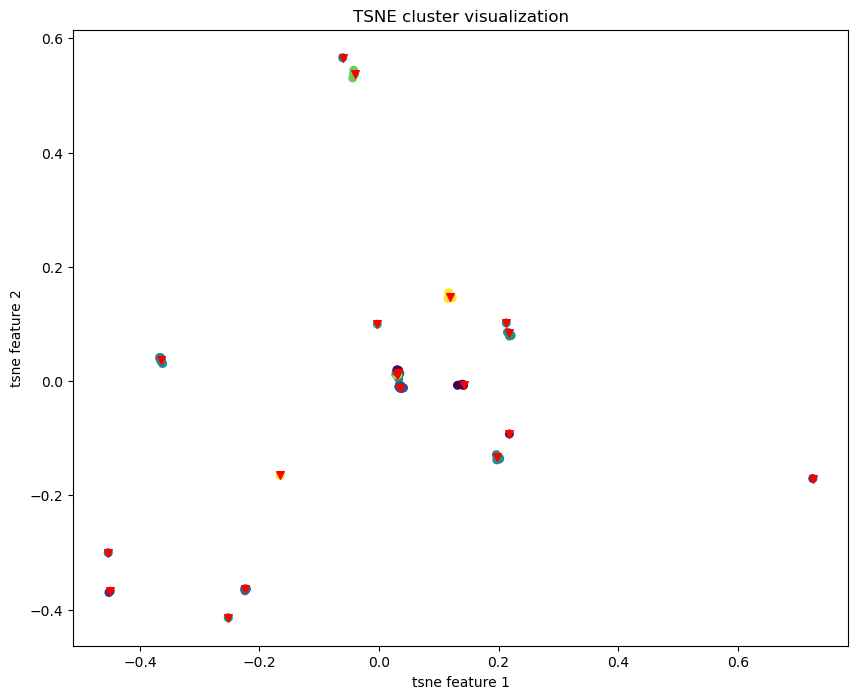

In [47]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import random

randClusters = random.sample(range(0, 1999), 20)
print('Clusters sampled: ')
print(randClusters)

subsetDf = centers_df[centers_df['Cluster'].isin(randClusters)]
subsetSoap = subsetDf.drop(columns='Cluster').values

subsetFullDf = df_pca[df_pca['Cluster'].isin(randClusters)]
subsetFullSoap = subsetFullDf.drop(columns='Cluster').values

tsne = TSNE(n_components=2, perplexity=5)
tsneFeatures = tsne.fit_transform(subsetSoap)

fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(subsetFullSoap[:, 0], subsetFullSoap[:, 1], s=30, c=subsetFullDf['Cluster'], cmap='viridis')
ax.scatter(subsetSoap[:, 0], subsetSoap[:, 1], s=30, c='red', marker='v')

ax.set_xlabel('tsne feature 1')
ax.set_ylabel('tsne feature 2')
ax.set_title('TSNE cluster visualization')

In [51]:
charge0_vals = set(df_charged['charge0'].to_list())
charge1_vals = set(df_charged['charge1'].to_list())


print(charge0_vals)
print(charge1_vals)


{1.0, 2.0, -2.0, -6.0, -5.0, -4.0, -3.0, -1.0}
{1.0, -1.0}


In [65]:
# print(df_charged.query("charge0 < -4")['lig_idx_list'].to_list())
df_charged.query("charge0 < -4")

,PDBID,full_PDBID,subdir,resnr,restype,reschain,prot_idx_list,resnr_lig,restype_lig,reschain_lig,...,protcoo_y,protcoo_z,natoms0,charge0,smiles0,natoms1,charge1,smiles1,elements,xyz
3tvl_3PO_B_231_190_LYS_1-12_2914,3tvl,3tvl_3PO_B_231,pdbbind_opt_sm/,190,LYS,B,2914,1,UNL,Z,...,-1.103,48.603,13.0,-5.0,O=P([O-])([O-])OP(=O)([O-])OP(=O)([O-])[O-],8.0,1.0,C[NH3+],P O O O P O O O P O O O O C H H N H H H H,14.660 -0.961 50.360 13.734 -1.221 51.539 15.8...
5tmp_Z5A_A_214_100_ARG_20-23_1640-1646,5tmp,5tmp_Z5A_A_214,pdbbind_opt_sm/,100,ARG,A,1640 1643 1646,1,UNL,Z,...,105.684,16.785,29.0,-5.0,CO[P@](=O)([O-])O[P@@](=O)([O-])O[P@](=O)([O-]...,13.0,1.0,CNC(N)=[NH2+],C O P O O O P O O O P O O O P O O O P O O O C ...,20.579 102.588 17.728 21.239 103.306 16.735 20...
6pvu_P0S_B_201_8_LYS_3-24_126,6pvu,6pvu_P0S_B_201,pdbbind_opt_sm/,8,LYS,B,126,1,UNL,Z,...,-28.153,30.589,22.0,-5.0,O=PO[P@@](=O)([O-])OP[O-].[O-]P.[O-]P.[O-]P,8.0,1.0,C[NH3+],O O O O O O O O O P P P P P P H H H H H H H C ...,-41.808 -22.262 31.446 -47.553 -23.989 31.879 ...
2ov4_AQP_A_400_196_LYS_15-31_3168,2ov4,2ov4_AQP_A_400,pdbbind_opt_sm/,196,LYS,A,3168,1,UNL,Z,...,19.816,35.274,21.0,-5.0,CO[P@@](=O)([O-])O[P@](=O)([O-])O[P@](=O)([O-]...,8.0,1.0,C[NH3+],C O P O O O P O O O P O O O P O O O H H H C H ...,54.500 23.084 36.895 53.167 23.399 37.351 52.1...
3tvl_3PO_B_231_54_ARG_5-13_897-903,3tvl,3tvl_3PO_B_231,pdbbind_opt_sm/,54,ARG,B,897 900 903,1,UNL,Z,...,-7.608,47.865,13.0,-5.0,O=P([O-])([O-])OP(=O)([O-])OP(=O)([O-])[O-],13.0,1.0,CNC(N)=[NH2+],P O O O P O O O P O O O O C H H N C N H H N H ...,14.660 -0.961 50.360 13.734 -1.221 51.539 15.8...
6pvu_P0S_B_201_42_LYS_1-23_652,6pvu,6pvu_P0S_B_201,pdbbind_opt_sm/,42,LYS,B,652,1,UNL,Z,...,-22.075,28.992,22.0,-5.0,O=P.O=P([O-])(OP[O-])OP[O-].[O-]P.[O-]P,8.0,1.0,C[NH3+],O O O O O O O O O P P P P P P H H H H H H H C ...,-41.808 -22.262 31.446 -47.553 -23.989 31.879 ...
6pvv_5FA_B_201_8_LYS_32-35_153,6pvv,6pvv_5FA_B_201,pdbbind_opt_sm/,8,LYS,B,153,1,UNL,Z,...,12.229,30.140,25.0,-6.0,CO[P@@](=O)([O-])O[P@@](=O)([O-])O[P@](=O)([O-...,8.0,1.0,C[NH3+],O C P O O O P O O O P O O O P O O O P O O O H ...,43.570 11.763 35.932 42.671 11.764 34.819 45.0...
5eje_AP5_B_301_14_LYS_4-16_264,5eje,5eje_AP5_B_301,pdbbind_opt_sm/,14,LYS,B,264,1,UNL,Z,...,-76.278,-22.703,29.0,-5.0,CO[P@](=O)([O-])O[P@](=O)([O-])O[P@](=O)([O-])...,8.0,1.0,C[NH3+],P O O O P O O O P O O O P O O O P O O O C O C ...,18.246 -71.536 -19.365 18.296 -70.577 -20.529 ...
4x8o_AP5_B_301_37_ARG_17-39_628-634,4x8o,4x8o_AP5_B_301,pdbbind_opt_sm/,37,ARG,B,628 631 634,1,UNL,Z,...,9.718,-71.901,29.0,-5.0,CO[P@](=O)([O-])O[P@](=O)([O-])O[P@](=O)([O-])...,13.0,1.0,CNC(N)=[NH2+],P O O O P O O O P O O O P O O O P O O O C O C ...,-19.858 18.841 -72.217 -20.873 18.907 -71.117 ...
5j5o_6G0_B_301_133_LYS_9-25_2231,5j5o,5j5o_6G0_B_301,biolip2_opt/,133,LYS,B,2231,1,UNL,Z,...,42.416,-46.720,21.0,-5.0,CO[P@@](=O)([O-])O[P@](=O)([O-])O[P@@](=O)([O-...,8.0,1.0,C[NH3+],O P O O O P O O O P O O O P O O O C H H H C H ...,-55.632 38.305 -43.305 -55.626 38.405 -44.915 ...


In [4]:
df = pd.read_csv('salt_bridge_center.csv')

df_neutral = df.query('charge0 == 0.0 or charge1 == 0.0')
df_neutral

# for index, row in df.iterrows():
#     if row['charge0'] == 0.0 or row['charge1'] == 0.0:


,Unnamed: 0,PDBID,full_PDBID,subdir,resnr,restype,reschain,prot_idx_list,resnr_lig,restype_lig,...,protcoo_y,protcoo_z,natoms0,charge0,smiles0,natoms1,charge1,smiles1,elements,xyz
1,3vha_VHA_A_237_84_ASP_22-27_1387-1388,3vha,3vha_VHA_A_237,pdbbind_opt_sm/,84,ASP,A,1387 1388,1,UNL,...,7.608,11.155,12.0,0.0,NC1=NC=CC=N1,7.0,-1.0,CC(=O)[O-],C N C C N C N H H H H H C H H C O O H,10.616 4.091 12.671 9.438 4.664 12.532 10.755 ...
7,6dim_GJP_A_701_333_HIS_12-13_5276-5282,6dim,6dim_GJP_A_701,pdbbind_opt_sm/,333,HIS,A,5276 5282,1,UNL,...,-8.891,34.316,19.0,-1.0,O=C([O-])C1=CC2=CC=CC=C2N=C1,9.0,0.0,C1=CNC=N1,C C C C C C C C N C C O O H H H H H H C N H C ...,-6.788 -14.803 32.273 -6.650 -15.837 31.318 -7...
9,1bir_2GP_B_107_197_HIS_1-4_2786-2792,1bir,1bir_2GP_B_107,biolip2_opt/,197,HIS,B,2786 2792,1,UNL,...,4.886,19.459,9.0,-2.0,COP(=O)([O-])[O-],9.0,0.0,C1=CNC=N1,P O O O C O H H H C N H C H C H N H,23.467 7.762 21.548 22.908 8.415 22.740 24.558...
10,6oxz_NJG_A_102_125_ASP_31_2077-2078,6oxz,6oxz_NJG_A_102,pdbbind_opt_sm/,125,ASP,A,2077 2078,1,UNL,...,58.430,13.120,23.0,0.0,CN(C)S(=O)(=O)C1=CC=CC=C1,7.0,-1.0,CC(=O)[O-],C C C C C C C C N O O S H H H H H H H H H H H ...,67.134 51.166 13.546 66.680 52.625 13.449 67.3...
16,2y7k_SAL_A_1302_117_HIS_2-3_1842-1848,2y7k,2y7k_SAL_A_1302,pdbbind_opt_sm/,117,HIS,A,1842 1848,1,UNL,...,22.368,75.062,14.0,-1.0,O=C([O-])C1=CC=CC=C1,9.0,0.0,C1=CNC=N1,C O O C C C C C C H H H H H C N H C H C H N H,25.779 18.933 73.897 24.905 19.840 73.805 26.0...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1983,3gz8_APR_C_302_97_ARG_29-30_1572-1578,3gz8,3gz8_APR_C_302,biolip2_opt/,97,ARG,C,1572 1575 1578,1,UNL,...,-16.326,-51.241,13.0,0.0,CO[C@H](C)O,13.0,1.0,CNC(N)=[NH2+],O O C C C H H H H H H H H C H H N C N H H N H ...,22.177 -11.447 -50.680 21.846 -13.764 -50.886 ...
1985,4ojr_2SQ_A_301_104_HIS_23-22_1651-1657,4ojr,4ojr_2SQ_A_301,pdbbind_opt_sm/,104,HIS,A,1651 1657,1,UNL,...,-9.419,14.453,7.0,-1.0,CC(=O)[O-],9.0,0.0,C1=CNC=N1,C C O O H H H C N H C H C H N H,-46.140 -12.778 15.135 -46.581 -12.387 13.737 ...
1989,1u1w_3HA_A_700_75_HIS_1-3_1153-1159,1u1w,1u1w_3HA_A_700,pdbbind_opt_sm/,75,HIS,A,1153 1159,1,UNL,...,27.170,23.170,14.0,-1.0,O=C([O-])C1=CC=CC=C1,9.0,0.0,C1=CNC=N1,O C O C C C C C C H H H H H C N H C H C H N H,8.160 30.258 23.694 7.591 31.168 23.052 7.189 ...
1992,3q9o_NAD_A_700_457_HIS_24-27_7145-7151,3q9o,3q9o_NAD_A_700,biolip2_opt/,457,HIS,A,7145 7151,1,UNL,...,28.217,88.812,17.0,-2.0,CO[P@@](=O)([O-])O[P@](=O)([O-])OC,9.0,0.0,C1=CNC=N1,P O O O C O P O O O C H H H H H H C N H C H C ...,32.736 31.734 92.696 34.109 31.887 92.185 32.5...
